# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

torch.manual_seed(42)
torch.set_num_threads(1)

## Step 2 — Upload the dataset

In [2]:
# Supports both Colab and a local notebook folder.
candidates = [Path("Lab_11_QnA_Dataset.csv"),
              Path("/content/Lab_11_QnA_Dataset.csv"),
              Path("/content/Lab_11_QnA_Dataset_Download.csv"),
              Path("../upload/Lab_11_QnA_Dataset.csv")]
dataset_path = next((path for path in candidates if path.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Upload Lab_11_QnA_Dataset.csv to the notebook folder.")
df = pd.read_csv(dataset_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
import re
from collections import Counter

# Lowercase and remove punctuation consistently for training and plotting.
def tokenize(text):
    return re.sub(r"[^a-z0-9\s]", " ", text.lower()).split()

df["question"] = df["question"].str.lower()
tokenized_questions = df["question"].map(tokenize)
counts = Counter(word for words in tokenized_questions for word in words)
word_index = {word: i + 1 for i, (word, _) in enumerate(counts.most_common())}
index_word = {index: word for word, index in word_index.items()}
max_length = max(map(len, tokenized_questions))
X = torch.zeros((len(df), max_length), dtype=torch.long)
for i, words in enumerate(tokenized_questions):
    X[i, :len(words)] = torch.tensor([word_index[word] for word in words])
y = torch.tensor(df["answer_id"].values, dtype=torch.long)
assert sorted(df["answer_id"].unique()) == list(range(df["answer_id"].nunique()))
print("Input shape:", tuple(X.shape))

Input shape: (168, 11)


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(word_index) + 1, 16, padding_idx=0)
        # Input shape is [batch, sequence, embedding].
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        mask = x.ne(0)
        states, _ = self.rnn(self.emb(x))
        scores = self.att(states).squeeze(-1)
        scores = scores.masked_fill(~mask, float("-inf"))
        weights = torch.softmax(scores, dim=1)
        context = (states * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
model.train()
for epoch in range(50):
    optimizer.zero_grad()
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:2d}: loss = {loss.item():.4f}")

model.eval()
with torch.no_grad():
    logits, attention = model(X)
    accuracy = (logits.argmax(dim=1) == y).float().mean().item()
assert torch.allclose(attention.sum(dim=1), torch.ones(len(X)), atol=1e-6)
assert torch.all(attention[X == 0] == 0)
print(f"Training finished! Training accuracy: {accuracy:.1%}")

Epoch 10: loss = 1.7995
Epoch 20: loss = 0.9700
Epoch 30: loss = 0.4139
Epoch 40: loss = 0.1339
Epoch 50: loss = 0.0523
Training finished! Training accuracy: 99.4%


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

Question: do you get hurt?
Highest attention: 'do' (0.6377)
Predicted answer ID: 0; actual: 0


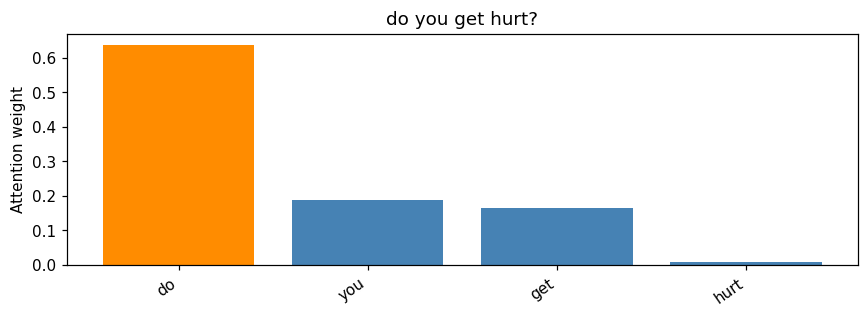

In [6]:
# Reusable plotting function: labels match the actual input tokens.
def plot_attention(row_index, ax):
    model.eval()
    with torch.no_grad():
        prediction, weights = model(X[row_index:row_index + 1])
    token_ids = X[row_index][X[row_index] != 0].tolist()
    words = [index_word[token_id] for token_id in token_ids]
    values = weights[0, :len(words)].cpu().tolist()
    best = max(range(len(values)), key=values.__getitem__)
    colors = ["darkorange" if i == best else "steelblue" for i in range(len(words))]
    ax.bar(range(len(words)), values, color=colors)
    ax.set_xticks(range(len(words)))
    ax.set_xticklabels(words, rotation=35, ha="right")
    ax.set_ylabel("Attention weight")
    ax.set_title(df.loc[row_index, "question"])
    predicted_id = prediction.argmax(dim=1).item()
    print(f"Question: {df.loc[row_index, 'question']}")
    print(f"Highest attention: {words[best]!r} ({values[best]:.4f})")
    print(f"Predicted answer ID: {predicted_id}; actual: {df.loc[row_index, 'answer_id']}")
    return words[best], values[best]

fig, ax = plt.subplots(figsize=(8, 3))
plot_attention(0, ax)
plt.tight_layout()
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: who programmed you?
Highest attention: 'you' (0.7385)
Predicted answer ID: 3; actual: 3
Question: what is your purpose?
Highest attention: 'purpose' (0.5046)
Predicted answer ID: 5; actual: 5
Question: are you smart?
Highest attention: 'smart' (0.9895)
Predicted answer ID: 11; actual: 11

Task 1 observations:
- who programmed you? -> highest-attention word: you (0.7385)
- what is your purpose? -> highest-attention word: purpose (0.5046)
- are you smart? -> highest-attention word: smart (0.9895)
Content words such as 'programmed', 'purpose', and 'smart' describe the main topic. A peak on one of them is consistent with its meaning. A peak on a function word is less intuitively relevant. Attention is learned for answer classification, so its largest weight is not guaranteed to mark the word a human considers most important.


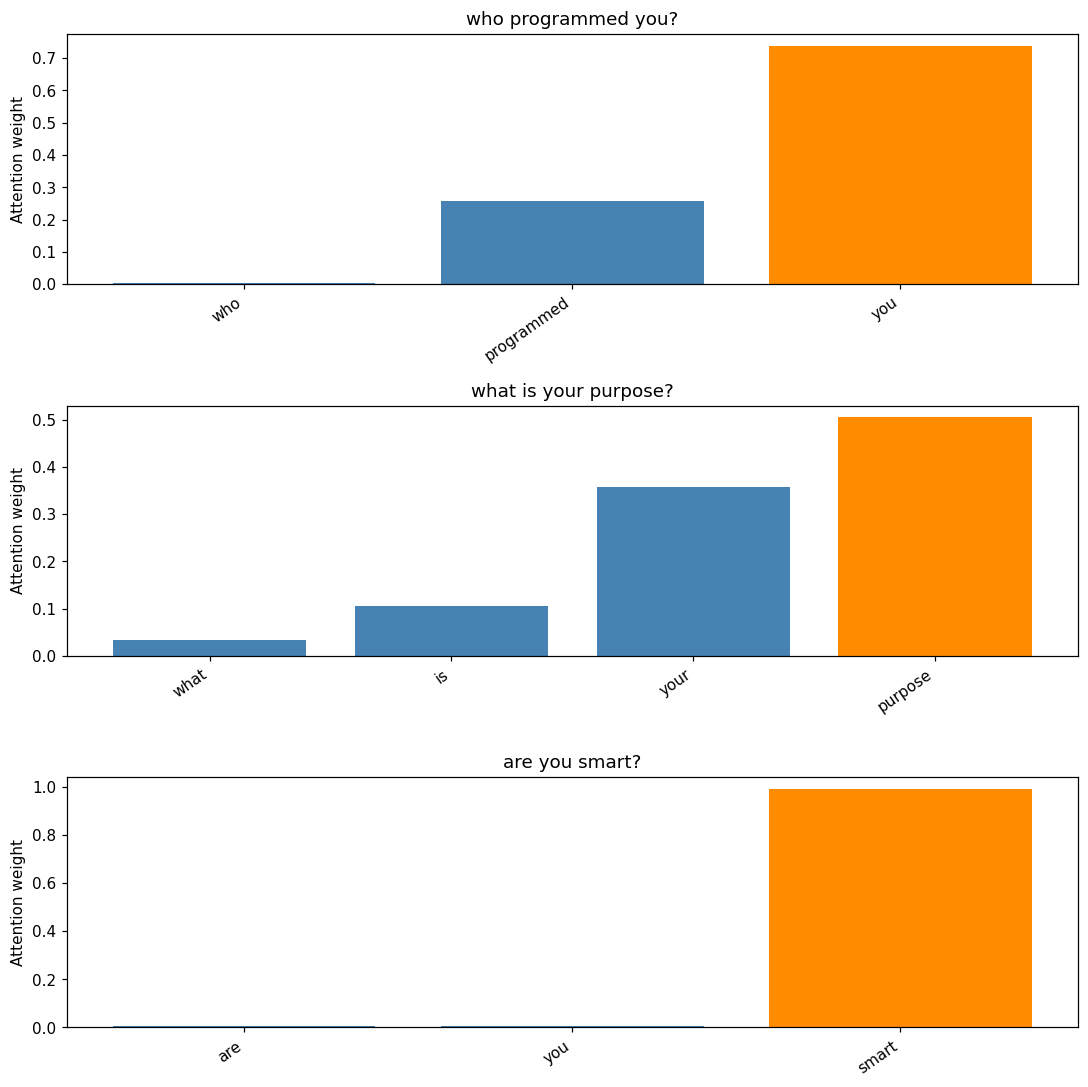

In [7]:
# Task 1: three questions from different answer groups.
selected_questions = ["who programmed you?", "what is your purpose?", "are you smart?"]
indices = [df.index[df["question"].eq(question)][0] for question in selected_questions]
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
task1_results = []
for row_index, ax in zip(indices, axes):
    task1_results.append(plot_attention(row_index, ax))
plt.tight_layout()
plt.show()
print("\nTask 1 observations:")
for question, (word, weight) in zip(selected_questions, task1_results):
    print(f"- {question} -> highest-attention word: {word} ({weight:.4f})")
print("Content words such as 'programmed', 'purpose', and 'smart' describe the main "
      "topic. A peak on one of them is consistent with its meaning. A peak on a "
      "function word is less intuitively relevant. Attention is learned for answer "
      "classification, so its largest weight is not guaranteed to mark the word "
      "a human considers most important.")

**Task 1 — Answer:** In this run, the highest-attention words were **you** (0.7385), **purpose** (0.5046), and **smart** (0.9895). The last two directly express the topic of their questions. **You** is less informative on its own, so the largest attention weight does not always identify the most meaningful word. However, the RNN state at that position also contains preceding context, including *programmed*. Attention weights therefore apply to contextual hidden states, not isolated word meanings.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: who programmed you?
Highest attention: 'you' (0.7385)
Predicted answer ID: 3; actual: 3
Question: which company programmed you?
Highest attention: 'company' (0.8969)
Predicted answer ID: 3; actual: 3

Task 2 observations:
The highest-attention words are 'you' and 'company'.
The model focuses most on different words, even though both questions ask about its creator. Different wording can change the attention pattern.
Attention depends on the full sequence: each RNN state represents the current word and preceding context. Similar meanings therefore do not require identical weights or the same top word. These results describe this small training set; attention alone does not prove semantic understanding or generalization.


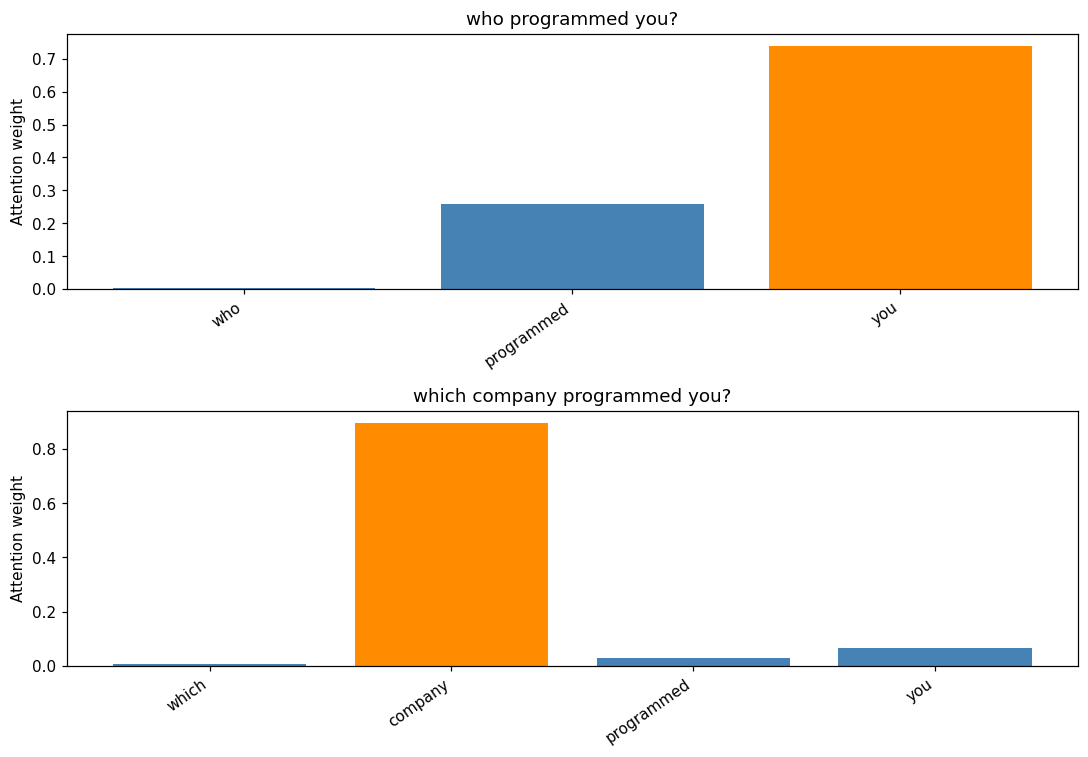

In [8]:
# Task 2: two paraphrases in the same answer group.
pair = ["who programmed you?", "which company programmed you?"]
indices = [df.index[df["question"].eq(question)][0] for question in pair]
assert df.loc[indices, "answer_id"].nunique() == 1
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
task2_results = []
for row_index, ax in zip(indices, axes):
    task2_results.append(plot_attention(row_index, ax))
plt.tight_layout()
plt.show()
first_word, second_word = task2_results[0][0], task2_results[1][0]
print("\nTask 2 observations:")
print(f"The highest-attention words are '{first_word}' and '{second_word}'.")
if first_word == second_word:
    print("The model focuses most on the same word in both paraphrases, "
          "consistent with a shared cue for the same answer category.")
else:
    print("The model focuses most on different words, even though both questions "
          "ask about its creator. Different wording can change the attention pattern.")
print("Attention depends on the full sequence: each RNN state represents the current "
      "word and preceding context. Similar meanings therefore do not require identical "
      "weights or the same top word. These results describe this small training set; "
      "attention alone does not prove semantic understanding or generalization.")

**Task 2 — Answer:** Both questions ask who created the chatbot and belong to answer group 3. The first question focuses most on **you** (0.7385), whereas the second focuses most on **company** (0.8969). Both receive the correct predicted answer group. This shows that paraphrases can produce different attention patterns while supporting the same classification. Attention depends on wording and context; identical meaning does not require identical top-attention words. Numerical results can vary across software versions.